# Historical Volatility Baseline Models & Walk-Forward Evaluation — Quantamental AI

**Module:** AI Risk Lab (Module B) — Phase 3, Step 3.1  
**Notebook:** `08_historical_baseline_analysis.ipynb`  
**Horizon:** 21 Trading Days (Configurable, $\sqrt{252}$ Annualization)  
**Units:** Forecasts and targets are **annualized volatility** ($\sigma$, decimal, e.g., `0.20` = 20%); QLIKE converts these internally to **annualized variance** ($\sigma^2$).  
**Standards:** Strictly causal lagged features ($\tau \le t - 1$), chronological walk-forward splits with purge gap $\ge h$, normalized Patton (2011) QLIKE, explicit `ForecastFloorPolicy` (`min_volatility = 1e-3`).

---

## Objectives
1. Construct strictly causal log-return features (`build_volatility_features`) with zero look-ahead bias.
2. Evaluate five historical baseline models on identical expanding walk-forward folds.
3. Compare **raw** vs **post-processed (floored)** OLS/Ridge predictions, including exact flooring counts and percentages.
4. Report **pooled out-of-sample** metrics separately from **macro fold-averaged** metrics using normalized Patton (2011) QLIKE:
$$L_{\text{QLIKE}}(\sigma^2_{\text{actual}}, \sigma^2_{\text{pred}}) = \frac{\sigma^2_{\text{actual}}}{\sigma^2_{\text{pred}}} - \ln\!\left(\frac{\sigma^2_{\text{actual}}}{\sigma^2_{\text{pred}}}\right) - 1 \ge 0.$$

In [1]:
import sys
from pathlib import Path

def find_repo_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / 'backend' / 'app').is_dir():
            return candidate
    raise RuntimeError('Could not locate Quantamental_AI repository root.')

REPO_ROOT = find_repo_root()
BACKEND_DIR = REPO_ROOT / 'backend'
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

def check(condition: bool, message: str) -> None:
    if not condition:
        raise AssertionError(f'Validation failed: {message}')

print(f'Repository root: {REPO_ROOT}')

Repository root: /Users/lakshyabapna/Desktop/Quantamental_AI


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app.ai_engine import (
    DEFAULT_MIN_ANNUALIZED_VOL,
    OLSBaseline,
    RidgeBaseline,
    RollingVolBaseline,
    WalkForwardSplitter,
    aggregate_metrics,
    apply_volatility_floor,
    build_volatility_features,
    evaluate_baselines,
    scale_fold_features,
)
from app.portfolio_engine.returns import calculate_log_returns

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
print(f'Production ai_engine imported (default floor = {DEFAULT_MIN_ANNUALIZED_VOL:.1e} annualized vol).')

Production ai_engine imported (default floor = 1.0e-03 annualized vol).


## 1. Deterministic Price Series & Feature Construction

We generate a deterministic 4-year (~1,000 trading days) regime-switching synthetic NSE equity price series and benchmark series, then build the anti-leakage `FeatureDataset` for `horizon_days=21`.

In [3]:
rng = np.random.default_rng(2026)
n_days = 1000
dates = pd.bdate_range('2020-01-01', periods=n_days)

# Regime-switching volatility: calm (1% daily) vs elevated (2.4% daily)
regime_vol = np.where((np.arange(n_days) % 180) < 110, 0.010, 0.024)
bm_rets = rng.normal(0.0003, regime_vol * 0.85, size=n_days)
idio_rets = rng.normal(0.0001, regime_vol * 0.55, size=n_days)
asset_rets = 1.05 * bm_rets + idio_rets

asset_prices = pd.Series((1500.0 * np.exp(np.cumsum(asset_rets))).tolist(), index=dates, name='RELIANCE.NS')
bm_prices = pd.Series((18000.0 * np.exp(np.cumsum(bm_rets))).tolist(), index=dates, name='^NSEI')

log_rets = calculate_log_returns(asset_prices, aligned=True)
dataset = build_volatility_features(
    asset_prices,
    benchmark_prices=bm_prices,
    horizon_days=21,
)

check(dataset.X.shape[0] > 800, 'Expected > 800 valid aligned feature rows')
check(dataset.horizon_days == 21, 'Expected default 21-day horizon')
print(f'Feature matrix shape: {dataset.X.shape}')
print(f'Target (annualized vol) range: [{dataset.y.min():.4f}, {dataset.y.max():.4f}]')
print(f'Target (annualized variance) range: [{(dataset.y**2).min():.6f}, {(dataset.y**2).max():.6f}]')

Feature matrix shape: (916, 18)
Target (annualized vol) range: [0.1038, 0.5099]
Target (annualized variance) range: [0.010768, 0.259971]


## 2. Walk-Forward Evaluation: Pooled OOS vs Macro Fold-Averaged Metrics & Flooring Diagnostics

Each expanding fold uses `train_size=252`, `test_size=63`, and `purge_gap >= 21`. We apply `min_volatility = 1e-3` (0.1% annualized volatility) explicitly as a post-processing floor while preserving raw OLS/Ridge predictions for diagnostics.

In [4]:
fold_results = evaluate_baselines(
    asset_prices,
    benchmark_prices=bm_prices,
    horizon_days=21,
    train_size=252,
    test_size=63,
    mode='expanding',
    min_volatility=1e-3,
)

summary_df = aggregate_metrics(fold_results)
check(len(summary_df) == 5, 'Expected all 5 baseline models in summary')
check((summary_df['pooled_qlike'] >= 0.0).all(), 'Normalized QLIKE must be non-negative')

pooled_cols = ['model_name', 'pooled_rmse', 'pooled_mae', 'pooled_r2', 'pooled_qlike', 'n_floored', 'floored_pct']
print('=== Pooled Out-of-Sample Metrics (630 OOS observations, Post-Processed) ===')
print(summary_df[pooled_cols].round(4).to_string(index=False))

raw_vs_proc_cols = ['model_name', 'raw_pooled_rmse', 'pooled_rmse', 'raw_pooled_mae', 'pooled_mae', 'raw_pooled_r2', 'pooled_r2', 'n_floored', 'floored_pct']
print('\n=== Raw vs Post-Processed (Floored) Pooled OOS Metrics ===')
print(summary_df[raw_vs_proc_cols].round(4).to_string(index=False))

macro_cols = ['model_name', 'macro_rmse', 'macro_mae', 'macro_r2', 'macro_qlike', 'n_folds']
print('\n=== Macro Fold-Averaged Metrics (Unweighted Mean Across 10 Folds) ===')
print(summary_df[macro_cols].round(4).to_string(index=False))

=== Pooled Out-of-Sample Metrics (630 OOS observations, Post-Processed) ===
      model_name  pooled_rmse  pooled_mae  pooled_r2  pooled_qlike  n_floored  floored_pct
   ridge_alpha_1       0.0982      0.0814     0.1379        4.1741          0       0.0000
             ols       0.0992      0.0826     0.1188       66.1700          1       0.1587
 rolling_vol_21d       0.1038      0.0766     0.0367        0.4187          0       0.0000
 rolling_vol_63d       0.1329      0.1120    -0.5805        0.5414          0       0.0000
rolling_mean_21d       0.1829      0.1595    -1.9935        1.1796          0       0.0000

=== Raw vs Post-Processed (Floored) Pooled OOS Metrics ===
      model_name  raw_pooled_rmse  pooled_rmse  raw_pooled_mae  pooled_mae  raw_pooled_r2  pooled_r2  n_floored  floored_pct
   ridge_alpha_1           0.0982       0.0982          0.0814      0.0814         0.1379     0.1379          0       0.0000
             ols           0.0992       0.0992          0.0826      

## 3. Raw vs Post-Processed Out-of-Sample Predictions & Per-Fold RMSE Diagnostics

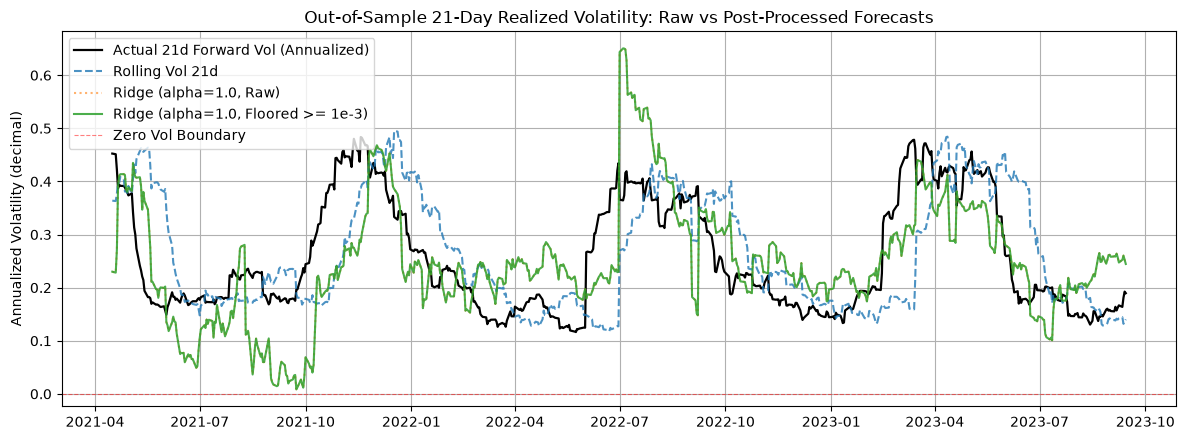

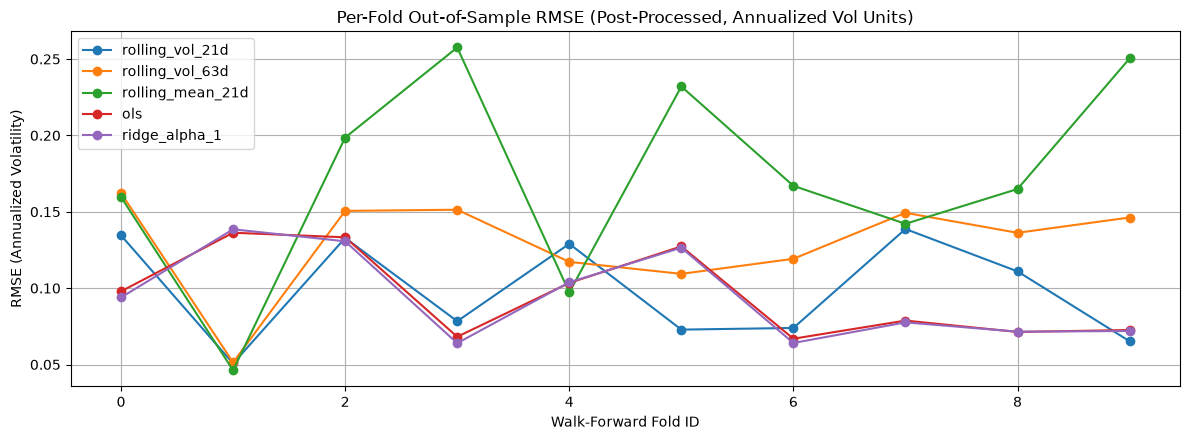

In [5]:
splitter = WalkForwardSplitter(
    mode='expanding',
    train_size=252,
    test_size=63,
    horizon_days=21,
)

oos_dates = []
oos_actual = []
oos_rv21 = []
oos_ridge_raw = []
oos_ridge_proc = []

for fold in splitter.split(dataset.X, dataset.y):
    test_idx = fold.test_indices.tolist()
    scaled = scale_fold_features(dataset.X, dataset.y, fold)

    rv21 = RollingVolBaseline(window=21)
    ridge = RidgeBaseline(alpha=1.0).fit(scaled.X_train, scaled.y_train)
    ridge_post = apply_volatility_floor(ridge.predict(scaled.X_test), min_volatility=1e-3)

    oos_dates.extend(dataset.X.index[test_idx])
    oos_actual.extend(dataset.y.iloc[test_idx].tolist())
    oos_rv21.extend(rv21.predict(dataset.X.iloc[test_idx]).tolist())
    oos_ridge_raw.extend(ridge_post.raw_predictions.tolist())
    oos_ridge_proc.extend(ridge_post.predictions.tolist())

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(oos_dates, oos_actual, label='Actual 21d Forward Vol (Annualized)', color='black', linewidth=1.6)
ax.plot(oos_dates, oos_rv21, label='Rolling Vol 21d', alpha=0.8, linestyle='--')
ax.plot(oos_dates, oos_ridge_raw, label='Ridge (alpha=1.0, Raw)', alpha=0.6, linestyle=':')
ax.plot(oos_dates, oos_ridge_proc, label='Ridge (alpha=1.0, Floored >= 1e-3)', alpha=0.85)
ax.axhline(0.0, color='red', linewidth=0.8, linestyle='--', alpha=0.5, label='Zero Vol Boundary')
ax.set_title('Out-of-Sample 21-Day Realized Volatility: Raw vs Post-Processed Forecasts')
ax.set_ylabel('Annualized Volatility (decimal)')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
for model_name, metrics_list in fold_results.items():
    fold_ids = [m.fold_id for m in metrics_list]
    fold_rmses = [m.rmse for m in metrics_list]
    ax.plot(fold_ids, fold_rmses, marker='o', label=model_name)
ax.set_title('Per-Fold Out-of-Sample RMSE (Post-Processed, Annualized Vol Units)')
ax.set_xlabel('Walk-Forward Fold ID')
ax.set_ylabel('RMSE (Annualized Volatility)')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Gate 3.1 Remediation Summary

- Strictly causal feature pipeline (`tau <= t - 1`) verified.
- Explicit `ForecastFloorPolicy(min_volatility=1e-3)` preserves raw OLS/Ridge predictions while ensuring strictly positive variance forecasts for normalized Patton (2011) QLIKE.
- Pooled out-of-sample metrics and macro fold-averaged metrics are reported separately on identical OOS observations.
- Ready for independent review.